# Immuno Compass · Notebook 01: Load and inspect (Day 1)

**Goal today:** open all the data tables and *look* at them before doing anything else.

**Finish line:** we know
1. which columns hold the **number of patients tested (n)** and the **number of ADA-positive patients (y)**,
2. which column **links** the tables together,
3. what **surprises** in the data we must handle on Day 2.

> 🧒 *Simple version:* before cooking, we open every box in the fridge and check what's inside.

## 0 · Setup: install and import tools

In [1]:
# Install the extra tools (Colab already has pandas, numpy, matplotlib).
# The '-q' flag keeps the install output quiet.
import sys
if "google.colab" in sys.modules:
    !pip install -q pymc arviz shap xgboost statsmodels biopython joblib

import numpy as np                 # numbers and maths
import pandas as pd                # tables (like Excel inside Python)
import matplotlib.pyplot as plt    # charts
from pathlib import Path

np.random.seed(42)                 # makes random steps repeat the same way every run
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 60)

## 1 · Find the data files

The files live in `data/raw/` in the GitHub repo.

* **Running locally / after `git clone`:** nothing to do.
* **Running in Colab:** the cell below asks you to upload the 5 CSV files (pick them all at once).

In [2]:
# Look for the data folder in the usual places.
CANDIDATES = [Path("data/raw"), Path("../data/raw"), Path("/content/immuno-compass/data/raw")]
DATA_DIR = next((p for p in CANDIDATES if (p / "clinical_trials.csv").exists()), None)

if DATA_DIR is None and "google.colab" in sys.modules:
    # Colab fallback: upload the 5 CSV files by hand.
    from google.colab import files
    DATA_DIR = Path("/content/data/raw"); DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Please upload: clinical_trials.csv, aggregated_ada_values.csv, therapeutics.csv, sequences.csv, controlled_language.csv")
    for name, content in files.upload().items():
        (DATA_DIR / name).write_bytes(content)

assert DATA_DIR is not None, "Could not find data/raw/ — check where the CSV files are."
print("Using data from:", DATA_DIR)

Using data from: ../data/raw


## 2 · Load the five tables

In [3]:
trials = pd.read_csv(DATA_DIR / "clinical_trials.csv", low_memory=False)        # main diary: one row per group × timepoint
agg    = pd.read_csv(DATA_DIR / "aggregated_ada_values.csv", low_memory=False)  # same rows + ready-made summaries
thera  = pd.read_csv(DATA_DIR / "therapeutics.csv")                             # one row per medicine (ID card)
seqs   = pd.read_csv(DATA_DIR / "sequences.csv")                                # protein recipes (one row per chain)
vocab  = pd.read_csv(DATA_DIR / "controlled_language.csv")                      # dictionary of allowed values

for name, t in [("trials", trials), ("agg", agg), ("thera", thera), ("seqs", seqs), ("vocab", vocab)]:
    print(f"{name:7s} rows = {t.shape[0]:5d}   columns = {t.shape[1]}")

trials  rows =  3334   columns = 43
agg     rows =  3334   columns = 57
thera   rows =   218   columns = 24
seqs    rows =   222   columns = 8
vocab   rows =   111   columns = 4


### 2a · Every column, how much is missing, and an example value

In [4]:
def column_report(t):
    """One line per column: share missing, number of distinct values, a few examples."""
    return pd.DataFrame({
        "missing_share": t.isna().mean().round(2),
        "n_unique": t.nunique(),
        "examples": [list(t[c].dropna().astype(str).str[:35].unique()[:3]) for c in t.columns],
    })

print("=== clinical_trials ==="); display(column_report(trials))

=== clinical_trials ===


,missing_share,n_unique,examples
Manually Audited,0.00,2,"[False, True]"
Trial ID,0.00,726,"[CT0617, CT0001, CT0002]"
Trial External Source,0.00,4,"[Clinicaltrials.gov, EU Clinical Trials Register, FDA La..."
External Source Identifier,0.00,726,"[NCT00611208, 2004-001236-23, 2004-002815-10]"
Molecule Assessed for ADA INN Name,0.00,111,"[A-dmDT390-bisFV, Efalizumab, Infliximab]"
Therapeutic Assessed for ADA Trade name,0.00,134,"[RESIMMUNE, RAPTIVA, REMICADE]"
Therapeutic Assessed for ADA ID,0.00,139,"[PR_0011, PR_0127, PR_0177]"
IDC Row identifier,0.00,3323,"[CT0617_A1_001, CT0001_A1_002, CT0001_A1_003]"
Immunogenicity testing,0.00,147,"[Anti-A-Dmdt390-Bisfv Antibodies, Anti-Efalizumab Antibo..."
Therapeutic Exposure Status,0.00,3,"[Therapeutic Exposed, Therapeutic Naive, Therapeutic Naïve]"


In [5]:
print("=== therapeutics ==="); display(column_report(thera))

=== therapeutics ===


,missing_share,n_unique,examples
INN Name,0.00,147,"[Abciximab, Adalimumab, Brentuximab vedotin]"
Therapeutic ID,0.00,218,"[PR_0002, PR_0003, PR_0004]"
Trade name,0.00,210,"[REOPRO, HUMIRA, HYRIMOZ]"
Manufacturer,0.00,133,"[Eli Lilly, Abbvie, Sandoz]"
Labelled as Biosimilar?,0.00,2,"[No, Yes]"
Progeny of,0.69,15,"[PR_0003, PR_0020, PR_0070]"
Protein Description,0.00,151,"[Chimeric IgG1 Fab fragment of monoc, Human monoclonal a..."
Protein Modality,0.00,16,"[Antibody Fragments, Monoclonal antibody, Antibody-drug ..."
Species,0.00,5,"[Chimeric, Human, Bacterial]"
Antibody Backbone,0.00,10,"[Human Fab (CH1 IgG1), human IgG1, Not Applicable]"


In [6]:
print("=== sequences ==="); display(column_report(seqs))

=== sequences ===


,missing_share,n_unique,examples
Sequence ID,0.0,222,"[SQ_0163, SQ_0164, SQ_0003]"
Parental Molecule Therapeutic ID,0.0,120,"[PR_0002, PR_0003, PR_0010]"
INN Name,0.0,122,"[Abciximab, Adalimumab, Brentuximab vedotin]"
Chain Multiplicity,0.0,3,"[2, 1, 4]"
Chain Identifier,0.0,4,"[A, B, 1]"
Chain Descriptor,0.0,4,"[Heavy Chain 1, Light Chain 1, Domain 1]"
Amino Acid Sequence,0.0,219,"[EVQLQQSGTVLARPGASVKMSCEASGYTFTNYWMH, EIVLTQSPVTLSVTPGDS..."
Sequence Source,0.0,126,"[https://www.rcsb.org/sequence/6V4P , https://www.rcsb.o..."


In [7]:
# Only the columns that exist in 'agg' but NOT in 'trials' (the ready-made summaries).
extra = [c for c in agg.columns if c not in trials.columns]
print("=== aggregated_ada_values: extra columns ==="); display(column_report(agg[extra]))

=== aggregated_ada_values: extra columns ===


,missing_share,n_unique,examples
Therapeutic Assessed for ADA INN Name,0.00,111,"[Efalizumab, Infliximab, Adalimumab]"
Trial Arm Identifier,0.00,22,"[1, 2, 9]"
Percentage nADA+ patients reported,0.81,247,"[87.0, 46.0, 5.0]"
Percentage of patients with hypersensitivity or injection site reactions,0.66,706,"[3, 50, Hypersensitivity: 3.4]"
cohort_group_id,0.00,2319,"[PR_0127_Therapeutic Naive_CT0001_A1, PR_0127_Therapeuti..."
cohort_ADA,0.01,636,"[0.0, 11.8, 14.2]"
max_ADA_time,0.01,468,"[First (ft) period-baseline (week 0), Observational (ob)..."
N_at_max_ADA,0.01,440,"[286.0, 85.0, 105.0]"
trial_group_id,0.00,1127,"[PR_0127_Therapeutic Naive_CT0001, PR_0127_Therapeutic E..."
trial_ADA,0.01,664,"[0.0, 11.8, 8.446226415]"


## 3 · The target: n (tested) and y (ADA-positive)

> 🧒 *Example:* 100 kids tested, 15 made "catchers" (ADAs) → n = 100, y = 15, frequency = 15 %.

In [8]:
N_COL = "Number of Patients analyzed for ADA"   # n = patients tested
Y_COL = "Number of ADA+ patients"               # y = patients who made ADAs

n = pd.to_numeric(trials[N_COL], errors="coerce")
y = pd.to_numeric(trials[Y_COL], errors="coerce")

usable = n.notna() & y.notna() & (n > 0) & (y <= n)
print("rows with usable n and y:", usable.sum(), "of", len(trials))
print("impossible rows (y > n):", (y > n).sum())
print("rows with very small groups  n < 10:", (n[usable] < 10).sum(), "| n < 20:", (n[usable] < 20).sum())

freq = (y / n)[usable]
print(f"share of rows with 0 % ADA:   {(freq == 0).mean():.1%}")
print(f"pooled ADA frequency (all patients together): {y[usable].sum() / n[usable].sum():.1%}")
print("\nGroup size (n) summary:"); print(n[usable].describe().round(1))

rows with usable n and y: 3281 of 3334
impossible rows (y > n): 0
rows with very small groups  n < 10: 563 | n < 20: 917
share of rows with 0 % ADA:   39.1%
pooled ADA frequency (all patients together): 13.2%

Group size (n) summary:
count     3281.0
mean       125.8
std        299.9
min          1.0
25%         16.0
50%         55.0
75%        160.0
max      13769.0
Name: Number of Patients analyzed for ADA, dtype: float64


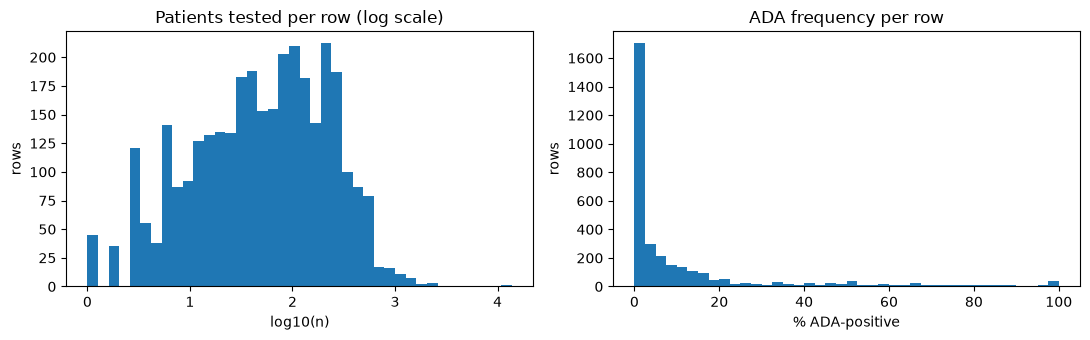

In [9]:
# Two quick pictures: how big are the groups, and what do ADA frequencies look like?
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.log10(n[usable]), bins=40)
ax[0].set_title("Patients tested per row (log scale)"); ax[0].set_xlabel("log10(n)"); ax[0].set_ylabel("rows")
ax[1].hist(freq * 100, bins=40)
ax[1].set_title("ADA frequency per row"); ax[1].set_xlabel("% ADA-positive"); ax[1].set_ylabel("rows")
plt.tight_layout(); plt.show()

## 4 · Surprise 1: the same patients appear in many rows

A study *arm* (one group of patients) is often measured at several **timepoints** (week 0, week 12, week 52…).
Those rows are **the same people**, so they are not independent observations.

In [10]:
arm_keys = ["Trial ID", "Therapeutic Assessed for ADA ID", "Therapeutic Exposure Status", "Trial Arm Description"]
rows_per_arm = trials.groupby(arm_keys).size()
print("distinct patient groups (arms):", len(rows_per_arm))
print("groups measured at more than one timepoint:", (rows_per_arm > 1).sum())
print("most rows for a single group:", rows_per_arm.max())
print("distinct cohort ids in the aggregated table:", agg["cohort_group_id"].nunique())

distinct patient groups (arms): 2324
groups measured at more than one timepoint: 391
most rows for a single group: 36
distinct cohort ids in the aggregated table: 2319


## 5 · Surprise 2: some rows are measured *before* treatment

ADAs at "baseline / week 0" existed **before** the medicine was given. We flag them now and decide on Day 2.

In [11]:
tp = trials["Trial Arm Timepoint Description"].astype(str).str.lower()
is_baseline = tp.str.contains(r"baseline|week 0\b|day 0\b|pre-dose|predose")
print("rows that look like pre-treatment timepoints:", is_baseline.sum())
display(trials.loc[is_baseline, "Trial Arm Timepoint Description"].value_counts().head(10))

rows that look like pre-treatment timepoints: 650


Trial Arm Timepoint Description
Treatment period-baseline           74
Baseline                            47
Treatment period: baseline          34
Treatment period (baseline)         31
Treatment period- baseline          25
Treatment period (week 0)           19
Treatment period (post baseline)    19
Treatment period: post baseline     18
Treatment period-post baseline      16
Expansion phase - post-baseline     16
Name: count, dtype: int64

## 6 · Surprise 3: dose is text, not a number

In [12]:
display(trials["Dosing Description"].dropna().sample(10, random_state=42).to_frame())

,Dosing Description
52,Patients received single dose of ofatumumab 3 mg sc
681,Participants who were canakinumab treatment naive and di...
1279,Participants with migraine received a single dose of ere...
943,"0.3 mg/kg, administered intravenously (iv) once every 4 ..."
203,"Participants with fl received lenalidomide, 10 mg capsul..."
2973,Avelumab 10 mg/kg iv infusion was administered every 2 w...
1323,Healthy participants received 21 mg erenumab by subcutan...
3272,Infliximab iv 4.6 mg/kg
1671,"Vedolizumab 300 mg, intravenous (iv) infusion, once at w..."
486,Participants received a single dose of placebo administe...


## 7 · How do the tables link together?

In [13]:
THERA_KEY = "Therapeutic Assessed for ADA ID"     # in trials
thera_ids = set(thera["Therapeutic ID"])            # in therapeutics
seq_ids   = set(seqs["Parental Molecule Therapeutic ID"])  # in sequences

print("distinct medicines in trials:", trials[THERA_KEY].nunique())
print(f"trial rows that find their medicine ID card: {trials[THERA_KEY].isin(thera_ids).mean():.1%}")
print(f"trial rows whose medicine has a protein sequence: {trials[THERA_KEY].isin(seq_ids).mean():.1%}")
print("\nRows per medicine (top 10) — a few medicines dominate:")
display(trials[THERA_KEY].value_counts().head(10))

distinct medicines in trials: 139
trial rows that find their medicine ID card: 100.0%
trial rows whose medicine has a protein sequence: 78.1%

Rows per medicine (top 10) — a few medicines dominate:


Therapeutic Assessed for ADA ID
PR_0335    268
PR_0048    134
PR_0345    131
PR_0306    129
PR_0119    113
PR_0242     94
PR_0003     91
PR_0347     86
PR_0240     84
PR_0062     77
Name: count, dtype: int64

## 8 · Candidate features: what values do they take?

In [14]:
for c in ["Therapeutic Route of Administration", "Therapeutic Exposure Status", "Disease Indication Category",
          "Trial Blinding Type", "Randomized or Not Randomized", "Therapeutic Comparator"]:
    print(f"\n--- {c} ---"); print(trials[c].value_counts(dropna=False).to_string())


--- Therapeutic Route of Administration ---
Therapeutic Route of Administration
Intravenous                    1959
Subcutaneous                   1284
Ophthalmic                       51
Intramuscular                    38
Not Applicable                    1
Subcutaneous or Intravenous       1

--- Therapeutic Exposure Status ---
Therapeutic Exposure Status
Therapeutic Exposed    2705
Therapeutic Naive       628
Therapeutic Naïve         1

--- Disease Indication Category ---
Disease Indication Category
Cancer and neoplasms                     1319
Inflammation and autoimmunity            1229
Neurological                              230
Cardiovascular                            103
Healthy Volunteer                          82
Musculoskeletal                            78
Unspecified                                68
Metobolic and endocrine disorders          65
Infectious diseases                        47
Renal and urogenital                       43
Non-inflammatory respiratory 

In [15]:
for c in ["Protein Modality", "Species", "Antibody Backbone", "Conjugate Modification", "Expression System"]:
    print(f"\n--- {c} ---"); print(thera[c].value_counts(dropna=False).to_string())


--- Protein Modality ---
Protein Modality
Monoclonal antibody           146
Hormone and Growth Factors     14
Enzyme                         11
Antibody-drug conjugate         8
Fc-Fusion                       8
Immunotoxin                     6
Monoclonal Antibody             6
Cytokine                        4
Blood Clotting Factors          4
Single-Domain Antibody          3
IgG-like Bispecific             2
All Other Multispecifics        2
Antibody Fragments              1
Antibody fragments              1
Peptide                         1
Antibody-drug Conjugate         1

--- Species ---
Species
Humanized    98
Human        84
Chimeric     24
Bacterial    10
Mouse         2

--- Antibody Backbone ---
Antibody Backbone
human IgG1                             125
Not Applicable                          43
Human IgG4                              19
human IgG2                              15
Human Fab (CH1 IgG1)                     7
VHH                                      3
ScFv 

## 9 · Day 1 findings (write-up)

* **Target:** n = `Number of Patients analyzed for ADA`, y = `Number of ADA+ patients`. 3,281 of 3,334 rows usable; no impossible rows.
* **Link:** `Therapeutic Assessed for ADA ID` (trials) ↔ `Therapeutic ID` (therapeutics) ↔ `Parental Molecule Therapeutic ID` (sequences). 100 % of trial rows match a medicine; ~78 % have a sequence → sequence experiment is a **go** (above the 50 % rule).
* **Repeated measures:** ~2,320 patient groups but 3,334 rows → use **one row per group** on Day 2 (e.g. the peak-ADA timepoint, `cohort_ADA` / `N_at_max_ADA` in the aggregated table).
* **Baseline rows:** ~650 rows look pre-treatment → flag and exclude from the target.
* **Dose:** free text → try to extract mg/kg or mg; otherwise drop it and say so.
* **Messy spellings:** "Naïve"/"Naive", "Monoclonal antibody"/"Monoclonal Antibody", "Not applicable"/"Not Applicable" → standardise on Day 2.
* **Imbalance:** 39 % of rows are 0 % ADA; one medicine has 268 rows → weight by n and use **grouped CV by medicine**.